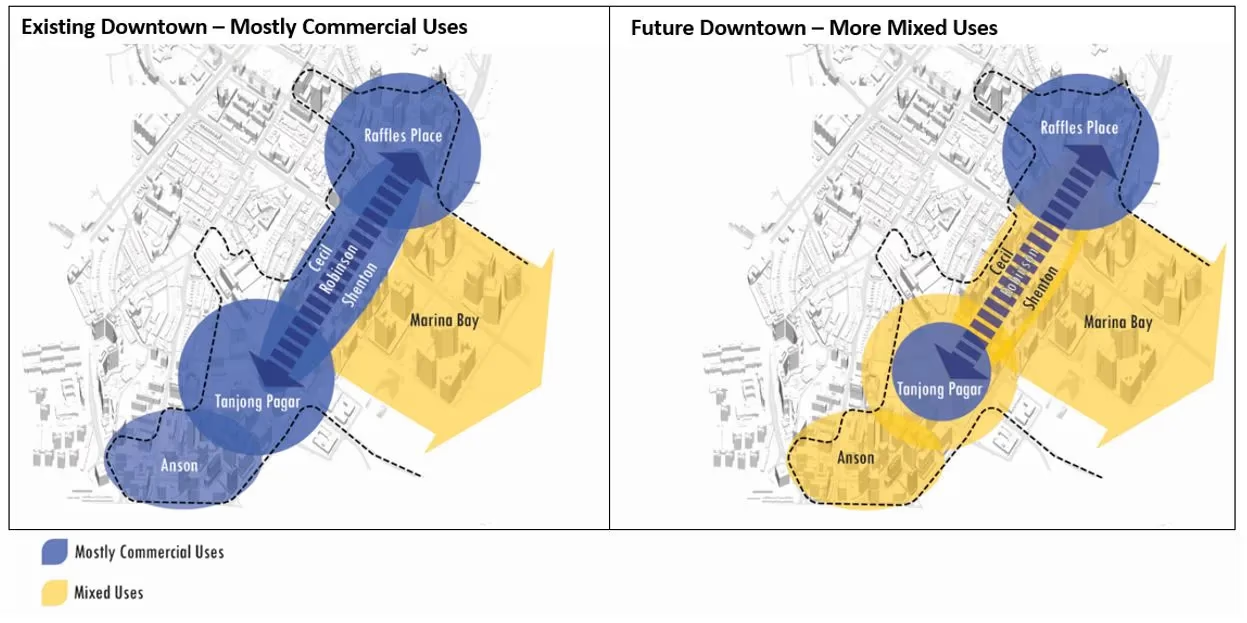

https://web.archive.org/web/20250723083823/https://www.ura.gov.sg/Corporate/Guidelines/Urban-Design/Downtown-Core

In [ ]:
%matplotlib inline
import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle

from utilities import add_north_arrow_2tone, add_segmented_scalebar, save_mpl_fig

SHP = "./../build/raw-data/subzone-census2010-shp/Subzone_Census2010.shp"

LAND = "#e6e8ee"
ACCENT, ACC_EDGE = "#c34534", "#7f2a1e"
INK, HAIR = "#20242b", "#c3c8d2"

In [ ]:
gdf_subzones = gpd.read_file(SHP)

gdf_downtown = (
    gdf_subzones.loc[lambda df_: df_["PLN_AREA_N"].str.upper() == "DOWNTOWN CORE"]
    .assign(
        SUBZONE_N=lambda df_: df_["SUBZONE_N"].str.replace(r"^DT - ", "", regex=True),
        _no=lambda df_: df_["SUBZONE_NO"].astype(int),
    )
    .sort_values("_no")
    .reset_index(drop=True)
)
assert len(gdf_downtown) == 12

In [ ]:
gdf_downtown_wm = gdf_downtown.to_crs(3857)  # Web Mercator, to sit on the tiles
gdf_downtown_wm["_pt"] = gdf_downtown_wm.geometry.representative_point()
gdf_singapore_wm = gdf_subzones.to_crs(3857).dissolve()

minx, miny, maxx, maxy = gdf_downtown_wm.total_bounds
pad = max(maxx - minx, maxy - miny) * 0.03
zy0, zy1 = miny - pad, maxy + pad
cx = (minx + maxx) / 2
half_w = (zy1 - zy0) * 1.35 / 2  # widen to a landscape panel
zx0, zx1 = cx - half_w, cx + half_w


def frame(ax_: plt.Axes) -> None:
    """Strip an axes' ticks and lighten its spines."""
    ax_.set_xticks([])
    ax_.set_yticks([])
    for spine in ax_.spines.values():
        spine.set_edgecolor(HAIR)
        spine.set_linewidth(0.8)


fig = plt.figure(figsize=(8.0, 4.3), dpi=150)
gs = fig.add_gridspec(
    2, 2, width_ratios=[1, 0.42], height_ratios=[0.62, 1], wspace=0.03, hspace=0.04
)
ax = fig.add_subplot(gs[:, 0])
ax_loc = fig.add_subplot(gs[0, 1])
ax_key = fig.add_subplot(gs[1, 1])

# core map
gdf_downtown_wm.plot(ax=ax, color=ACCENT, alpha=0.5, edgecolor=ACC_EDGE, linewidth=1.0)
ax.set_xlim(zx0, zx1)
ax.set_ylim(zy0, zy1)
ax.set_aspect("equal")
ctx.add_basemap(
    ax, source=ctx.providers.OpenStreetMap.Mapnik, attribution=False, zorder=-1
)
ax.add_patch(
    Rectangle(
        (zx0, zy0),
        zx1 - zx0,
        zy1 - zy0,
        facecolor="white",
        alpha=0.32,
        edgecolor="none",
        zorder=0,
    )
)
add_segmented_scalebar(
    ax,
    segments=[200, 400, 400, 400, 400],
    unit_type="m",
    location="lower right",
    height_fraction=0.010,
    unit_position="bottom",
    label_offset=0.005,
    unit_label_spacing=0.005,
    fontsize=8,
    unit_fontsize=9,
    map_crs="projected",
    unit_label="Meters",
)
for _, _row in gdf_downtown_wm.iterrows():
    ax.annotate(
        str(_row["_no"]),
        (_row["_pt"].x, _row["_pt"].y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="white",
        path_effects=[pe.withStroke(linewidth=1.8, foreground=ACC_EDGE)],
    )
add_north_arrow_2tone(ax)
frame(ax)

# locator inset
gdf_singapore_wm.plot(ax=ax_loc, color=LAND, edgecolor=HAIR, linewidth=0.4)
gdf_downtown_wm.plot(ax=ax_loc, color=ACCENT, edgecolor=ACC_EDGE, linewidth=0.25)
ax_loc.add_patch(
    Rectangle(
        (zx0, zy0), zx1 - zx0, zy1 - zy0, fill=False, edgecolor=INK, linewidth=0.9
    )
)
ax_loc.set_aspect("equal")
add_segmented_scalebar(
    ax_loc,
    segments=[5, 5],
    location="lower right",
    height_fraction=0.020,
    unit_position="right",
    label_offset=0.015,
    unit_label_spacing=0.015,
    fontsize=7,
    unit_fontsize=7,
    map_crs="projected",
    unit_label="km",
)
add_north_arrow_2tone(ax_loc, top_frac=0.82, height_frac=0.14, fontsize=7)
frame(ax_loc)

# numbered key
ax_key.set_xlim(0, 1)
ax_key.set_ylim(0, 1)
ax_key.set_axis_off()
names = list(gdf_downtown["SUBZONE_N"].str.title())
numbers = list(gdf_downtown["_no"])
step = 0.11
y0 = 0.5 + 2.5 * step
for _i in range(12):
    _col, _row_i = _i // 6, _i % 6
    _x = 0.06 + _col * 0.5
    _y = y0 - _row_i * step
    ax_key.text(
        _x,
        _y,
        str(numbers[_i]),
        ha="right",
        va="center",
        fontsize=7.8,
        fontweight="bold",
        color=INK,
    )
    ax_key.text(
        _x + 0.03, _y, names[_i], ha="left", va="center", fontsize=7.6, color=INK
    )

fig.subplots_adjust(left=0.012, right=0.988, top=0.985, bottom=0.03)
save_mpl_fig("../results/figures/empcenter-map")